# 《数据分析与可视化课程》第四周作业

**学号：42509068 　姓名：昝朝晖**

**研究对象：** 比亚迪股份有限公司（002594.SZ）

**研究期间：** 2019—2025 年

**研究题目：** 2019—2025 年，比亚迪的盈利增长是否与其股价表现同步？

**数据来源：** TuShare（Pro 接口，Token 由课程提供），全部数据由本 Notebook 实时获取，所有结论均来自下方实际计算结果，未使用任何编造数据。

## 一、公司名称与基本简介

比亚迪股份有限公司（BYD Company Limited），股票代码 **002594.SZ**，注册地深圳，属于**汽车整车**行业，2011 年 6 月 30 日在深圳证券交易所**主板**上市，实际控制人为王传福，目前股票状态为正常上市。

公司业务以新能源汽车为核心，同时覆盖动力电池与储能、手机部件及组装（电子代工）、光伏及轨道交通等多个领域。从收入结构看，汽车及相关产品是最主要的收入来源，手机部件及组装业务为重要补充，且近年来境外收入占比较高——**具体构成以下方代码实际获取的 2025 年报数据为准**。

In [1]:
import pandas as pd
import numpy as np
import tushare as ts
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# 读取 .env 中的 TuShare Token（不打印 Token 本身）
token = None
for env_path in (".env", r"D:\data analysis\.env"):
    try:
        with open(env_path, encoding="utf-8") as f:
            for line in f:
                if line.startswith("TUSHARE_TOKEN"):
                    token = line.split("=", 1)[1].strip().strip('"').strip("'")
                    break
    except FileNotFoundError:
        continue
    if token:
        break
assert token, "未找到 TUSHARE_TOKEN，请检查 .env 文件"

ts.set_token(token)
pro = ts.pro_api()
print("TuShare 初始化成功")

TuShare 初始化成功


In [2]:
# 公司基本信息（接口：stock_basic）
company = pro.stock_basic(ts_code="002594.SZ",
                          fields="ts_code,name,fullname,enname,industry,area,market,"
                                 "list_date,list_status,act_name")
display(company)
row = company.iloc[0]
assert row["ts_code"] == "002594.SZ"
assert row["fullname"] == "比亚迪股份有限公司"
print("核验通过：代码 002594.SZ，全称 比亚迪股份有限公司，行业", row["industry"],
      "，上市日期", row["list_date"])

,ts_code,name,fullname,enname,industry,area,market,list_date,list_status,act_name
0,002594.SZ,比亚迪,比亚迪股份有限公司,Byd Company Limited,汽车整车,深圳,主板,20110630,L,王传福


核验通过：代码 002594.SZ，全称 比亚迪股份有限公司，行业 汽车整车 ，上市日期 20110630


In [3]:
# 主营业务构成（接口：fina_mainbz，2025 年报，单位换算为亿元）
bz_p = pro.fina_mainbz(ts_code="002594.SZ", type="P", start_date="20240101", end_date="20251231")
bz_p = bz_p[bz_p["end_date"] == "20251231"].copy()
bz_p["收入(亿元)"] = (bz_p["bz_sales"] / 1e8).round(2)
bz_p["利润(亿元)"] = (bz_p["bz_profit"] / 1e8).round(2)
product = bz_p[bz_p["bz_item"] != "产品"][["bz_item", "收入(亿元)", "利润(亿元)"]]
total_row = bz_p[bz_p["bz_item"] == "产品"]["bz_sales"].iloc[0]
display(product.reset_index(drop=True))
# 断言：分部收入合计 ≈ 总收入（口径一致性验证）
assert abs(product["收入(亿元)"].sum() - total_row / 1e8) < 1, "分部收入与总收入不一致"
auto_share = product.loc[product["bz_item"].str.startswith("汽车"), "收入(亿元)"].iloc[0] / (total_row / 1e8)
print(f"核验通过：分部合计与营业总收入一致；汽车及相关产品收入占比 {auto_share:.1%}")

,bz_item,收入(亿元),利润(亿元)
0,汽车、汽车相关产品及其他产品,6486.46,1328.83
1,手机部件、组装及其他产品,1552.37,97.63
2,其他,0.83,0.15


核验通过：分部合计与营业总收入一致；汽车及相关产品收入占比 80.7%


In [4]:
# 境内外收入结构（接口：fina_mainbz，type='D'，2025 年报）
bz_d = pro.fina_mainbz(ts_code="002594.SZ", type="D", start_date="20240101", end_date="20251231")
bz_d = bz_d[bz_d["end_date"] == "20251231"].copy()
bz_d["收入(亿元)"] = (bz_d["bz_sales"] / 1e8).round(2)
region = bz_d[["bz_item", "收入(亿元)"]].reset_index(drop=True)
display(region)
total = region.loc[region["bz_item"] == "地区", "收入(亿元)"].iloc[0]
overseas = region.loc[region["bz_item"] == "境外", "收入(亿元)"].iloc[0]
print(f"2025 年营业总收入 {total:.2f} 亿元，其中境外收入 {overseas:.2f} 亿元，占 {overseas / total:.1%}")

,bz_item,收入(亿元)
0,境外,3107.41
1,地区,8039.65
2,中国(包括港澳台地区),4932.24


2025 年营业总收入 8039.65 亿元，其中境外收入 3107.41 亿元，占 38.7%


## 二、研究问题及其内涵介绍

**研究问题：2019—2025 年，比亚迪的盈利增长是否与其股价表现同步？**

“同步”是一个日常说法，直接检验无从下手。本研究把它拆解为三个可计算的子问题：

| 子问题 | 内涵 | 计算方法 | 对应图表 |
|---|---|---|---|
| **方向同步** | 盈利上涨的年份，股价是否也在上涨？ | 逐年比较净利润增速与股价收益率的符号，统计同向年份数 | 年度对照表 |
| **幅度同步** | 盈利增速越高，股价涨幅是否越大？ | 年度净利润增速与年度股价收益率的 Pearson、Spearman 相关系数 | 图4 散点图 |
| **趋势同步** | 盈利与股价的长期累计走势是否贴合？ | 双方均以 2018 年末 = 100 指数化后叠画 | 图3 双累计曲线 |

**关键口径说明（先于数据分析声明）：**

1. **盈利口径**：归母净利润（利润表 `n_income_attr_p`），增速为同比增速；样本为 2019—2025 共 **7 个年度**（2018 年数据仅作基期）。
2. **股价口径**：日线收盘价 × 复权因子 = **后复权价**，避免分红送转造成的除权失真；年度收益率按各年最后一个交易日的后复权价计算。
3. **时间对齐**：主口径为自然年对齐（2019 年盈利 ↔ 2019 年股价）；另做“滞后 1 年”对照（财报披露存在时滞），仅用于讨论。
4. **判定规则（预注册，防止看完数据再定标准）**：
   - Pearson r ≥ 0.5 且同向年份 ≥ 5/7 → **总体同步**；
   - 0.2 ≤ r < 0.5 或同向 4/7 → **弱同步 / 部分同步**；
   - r < 0.2 或同向 ≤ 3/7 → **不同步**。

## 三、数据采集、数据分析与问题解答

### 3.1 数据采集

| 数据 | TuShare 接口 | 关键字段 | 权限要求 |
|---|---|---|---|
| 交易日历 | `trade_cal` | is_open, cal_date | 基础权限 |
| 日线行情 | `daily` | close（**未复权**） | 基础权限 |
| 复权因子 | `adj_factor` | adj_factor（累计后复权因子） | 2000 积分 |
| 利润表 | `income` | total_revenue, n_income_attr_p | 2000 积分 |
| 财务指标 | `fina_indicator` | roe, netprofit_margin, netprofit_yoy | 2000 积分 |
| 沪深300 指数 | `index_daily` | close | 2000 积分 |
| 主营构成 | `fina_mainbz` | bz_item, bz_sales | 2000 积分 |

**（1）定位各年最后一个交易日，并与日行情交叉验证**

In [5]:
# 交易日历 + 日行情（2017-12 至 2026-01，覆盖 2018 年基期）
cal = pro.trade_cal(exchange="SSE", start_date="20171201", end_date="20260110")
open_days = cal[cal["is_open"] == 1]["cal_date"].sort_values().tolist()
YEAR_END = {}
for d in open_days:
    y = int(d[:4])
    if 2018 <= y <= 2025:
        YEAR_END[y] = d

daily = pro.daily(ts_code="002594.SZ", start_date="20171201", end_date="20260110")
daily = daily.sort_values("trade_date").reset_index(drop=True)
daily_max = daily.groupby(daily["trade_date"].str[:4])["trade_date"].max()

print("年份 | 日历口径最后交易日 | daily 口径 max(trade_date) | 验证")
for y in sorted(YEAR_END):
    dm = daily_max.get(str(y))
    print(f"{y} | {YEAR_END[y]} | {dm} | {'一致' if dm == YEAR_END[y] else '不一致'}")
    assert dm == YEAR_END[y], f"{y} 年末日期不一致"

cnt = daily.groupby(daily["trade_date"].str[:4]).size()
print("\n各年交易日数：", dict(cnt))
print("验证通过：8 个年末日期两口径全部一致，日线无缺失值", int(daily.isna().sum().sum()) == 0)
print("验证通过：日线", len(daily), "行，无重复日期", daily["trade_date"].duplicated().sum() == 0)

年份 | 日历口径最后交易日 | daily 口径 max(trade_date) | 验证
2018 | 20181228 | 20181228 | 一致
2019 | 20191231 | 20191231 | 一致
2020 | 20201231 | 20201231 | 一致
2021 | 20211231 | 20211231 | 一致
2022 | 20221230 | 20221230 | 一致
2023 | 20231229 | 20231229 | 一致
2024 | 20241231 | 20241231 | 一致
2025 | 20251231 | 20251231 | 一致

各年交易日数： {'2017': np.int64(21), '2018': np.int64(243), '2019': np.int64(244), '2020': np.int64(243), '2021': np.int64(243), '2022': np.int64(242), '2023': np.int64(242), '2024': np.int64(242), '2025': np.int64(243), '2026': np.int64(5)}
验证通过：8 个年末日期两口径全部一致，日线无缺失值 True
验证通过：日线 1968 行，无重复日期 True


**（2）复权处理：后复权价 = 收盘价 × 复权因子**

`daily` 返回的是未复权价，分红送股日会产生价格跳空，必须乘以 `adj_factor` 得到后复权价。注意：停牌日复权因子会被补齐而日线无数据，因此以日线为主表左连接复权因子。

In [6]:
adj = pro.adj_factor(ts_code="002594.SZ", start_date="20171201", end_date="20260110")
adj = adj.sort_values("trade_date").reset_index(drop=True)

df = daily.merge(adj[["trade_date", "adj_factor"]], on="trade_date", how="left")
assert len(df) == len(daily), "merge 行数异常"
assert df["adj_factor"].isna().sum() == 0, "复权因子缺失"
df["close_hfq"] = df["close"] * df["adj_factor"]
print(f"合并验证通过：{len(df)} 行，复权因子缺失 0 个")

# 复权因子跳变点 = 除权除息事件
df["adj_change"] = df["adj_factor"].diff()
jumps = df[df["adj_change"].fillna(0) > 0]
print(f"\n复权因子跳变（除权除息事件）共 {len(jumps)} 处：")
for _, r in jumps.iterrows():
    print(f"  {r['trade_date']}: {r['adj_factor'] - r['adj_change']:.3f} -> {r['adj_factor']:.3f}")

# 各年末价格：未复权 vs 后复权
rows = []
for y in sorted(YEAR_END):
    r = df[df["trade_date"] == YEAR_END[y]].iloc[0]
    rows.append({"年份": y, "日期": YEAR_END[y], "未复权收盘": r["close"],
                 "复权因子": r["adj_factor"], "后复权价": round(r["close_hfq"], 3)})
ye_table = pd.DataFrame(rows)
display(ye_table)
print("注意：2025 年末未复权价 97.72 元看似远低于 2024 年的 282.66 元，"
      "但后复权价为 307.81 vs 293.29——若不用复权价，收益率结论将完全相反。")

合并验证通过：1968 行，复权因子缺失 0 个

复权因子跳变（除权除息事件）共 9 处：
  20180816: 1.012 -> 1.012
  20180817: 1.012 -> 1.016
  20180828: 1.016 -> 1.016
  20190726: 1.016 -> 1.019
  20200818: 1.019 -> 1.020
  20230601: 1.020 -> 1.021
  20230728: 1.021 -> 1.025
  20240729: 1.025 -> 1.038
  20250729: 1.038 -> 3.150


,年份,日期,未复权收盘,复权因子,后复权价
0,2018,20181228,51.00,1.0160,51.816
1,2019,20191231,47.67,1.0190,48.576
2,2020,20201231,194.30,1.0200,198.186
3,2021,20211231,268.12,1.0200,273.482
4,2022,20221230,256.97,1.0200,262.109
5,2023,20231229,198.00,1.0250,202.950
6,2024,20241231,282.66,1.0376,293.288
7,2025,20251231,97.72,3.1499,307.808


注意：2025 年末未复权价 97.72 元看似远低于 2024 年的 282.66 元，但后复权价为 307.81 vs 293.29——若不用复权价，收益率结论将完全相反。


**（3）利润表年报数据（2018—2025，含 2018 年基期）**

同一报告期会因 `update_flag` 出现重复记录，规则：筛选合并报表（`report_type='1'`）→ 按公告日期取最新。

In [7]:
fields = ("ts_code,ann_date,end_date,report_type,update_flag,basic_eps,total_revenue,"
          "revenue,n_income,n_income_attr_p")
parts = []
for y in range(2018, 2026):
    p = pro.income(ts_code="002594.SZ", period=f"{y}1231", fields=fields)
    parts.append(p)
raw = pd.concat(parts, ignore_index=True)
print(f"原始返回 {len(raw)} 行（含 update_flag 重复版本）")

merged = raw[raw["report_type"] == "1"].copy()
print(f"筛选合并报表后 {len(merged)} 行，其中重复报告期 {merged['end_date'].duplicated().sum()} 行")
merged = merged.sort_values("ann_date").groupby("end_date").last().reset_index()
assert len(merged) == 8, "年报期数不是 8"
print("去重后", len(merged), "行")

merged["year"] = merged["end_date"].astype(str).str[:4].astype(int)
merged = merged.sort_values("year")
merged["营业总收入(亿元)"] = (merged["total_revenue"] / 1e8).round(2)
merged["归母净利润(亿元)"] = (merged["n_income_attr_p"] / 1e8).round(2)
merged["净利润含少数(亿元)"] = (merged["n_income"] / 1e8).round(2)

assert 2018 in set(merged["year"]) and 2025 in set(merged["year"]), "缺基期或2025年报"
assert (merged["归母净利润(亿元)"] > 0).all(), "存在非正净利润"
income_tbl = merged[["year", "ann_date", "basic_eps", "营业总收入(亿元)",
                     "归母净利润(亿元)", "净利润含少数(亿元)"]].rename(columns={"year": "年份"})
display(income_tbl)
print("验证通过：8 期齐全（2018 基期与 2025 年报均在），归母净利润 8 年全为正")

原始返回 13 行（含 update_flag 重复版本）
筛选合并报表后 13 行，其中重复报告期 5 行
去重后 8 行


,年份,ann_date,basic_eps,营业总收入(亿元),归母净利润(亿元),净利润含少数(亿元)
0,2018,20190328,0.93,1300.55,27.80,35.56
1,2019,20200422,0.50,1277.39,16.14,21.19
2,2020,20210330,1.47,1565.98,42.34,60.14
3,2021,20220330,1.06,2161.42,30.45,39.67
4,2022,20230329,5.71,4240.61,166.22,177.13
5,2023,20240327,10.32,6023.15,300.41,313.44
6,2024,20250325,13.84,7771.02,402.54,415.88
7,2025,20260328,3.58,8039.65,326.19,337.61


验证通过：8 期齐全（2018 基期与 2025 年报均在），归母净利润 8 年全为正


**（4）财务指标（口径与单位交叉验证）**

In [8]:
fparts = []
for y in range(2018, 2026):
    fp = pro.fina_indicator(ts_code="002594.SZ", period=f"{y}1231",
                            fields="ts_code,end_date,ann_date,roe,roe_waa,roe_dt,eps,"
                                   "grossprofit_margin,netprofit_margin,netprofit_yoy,profit_dedt")
    fparts.append(fp)
fina = pd.concat(fparts, ignore_index=True)
fina = fina.sort_values("ann_date").groupby("end_date").last().reset_index()
fina["year"] = fina["end_date"].astype(str).str[:4].astype(int)
fina = fina.sort_values("year").reset_index(drop=True)
assert len(fina) == 8
display(fina[["year", "roe", "roe_waa", "eps", "grossprofit_margin", "netprofit_margin", "netprofit_yoy"]])

# 验证1：比率单位是否为百分数 —— 自算净利率(含少数) vs 接口 netprofit_margin
chk = merged[["year", "净利润含少数(亿元)", "营业总收入(亿元)"]].merge(
    fina[["year", "netprofit_margin"]], on="year")
chk["自算净利率%"] = (chk["净利润含少数(亿元)"] / chk["营业总收入(亿元)"] * 100).round(2)
chk["差异"] = (chk["自算净利率%"] - chk["netprofit_margin"]).abs().round(3)
display(chk[["year", "自算净利率%", "netprofit_margin", "差异"]])
assert chk["差异"].max() < 0.05, "单位或口径不一致"
print(f"单位验证通过：最大差异 {chk['差异'].max()}（纯四舍五入）→ 接口比率单位为百分数，"
      "netprofit_margin 口径为『净利润(含少数)/营业总收入』")

,year,roe,roe_waa,eps,grossprofit_margin,netprofit_margin,netprofit_yoy
0,2018,5.0456,4.96,0.93,16.4003,2.7344,-31.6314
1,2019,2.8840,2.62,0.50,16.2944,1.6587,-41.9303
2,2020,7.4523,7.43,1.47,19.3785,3.8404,162.2730
3,2021,4.0083,3.73,1.06,13.0214,1.8355,-28.0823
4,2022,16.1305,16.14,5.71,17.0365,4.1770,445.8595
5,2023,24.0481,24.40,10.32,20.2148,5.2039,80.7243
6,2024,24.8437,26.05,13.84,19.4383,5.3517,33.9989
7,2025,15.1180,15.31,3.58,17.7445,4.1993,-18.9677


,year,自算净利率%,netprofit_margin,差异
0,2018,2.73,2.7344,0.004
1,2019,1.66,1.6587,0.001
2,2020,3.84,3.8404,0.000
3,2021,1.84,1.8355,0.005
4,2022,4.18,4.1770,0.003
5,2023,5.20,5.2039,0.004
6,2024,5.35,5.3517,0.002
7,2025,4.20,4.1993,0.001


单位验证通过：最大差异 0.005（纯四舍五入）→ 接口比率单位为百分数，netprofit_margin 口径为『净利润(含少数)/营业总收入』


**（5）沪深 300 基准指数（用于区分公司因素与市场整体因素）**

In [9]:
idx = pro.index_daily(ts_code="000300.SH", start_date="20171201", end_date="20260110")
idx["trade_date"] = idx["trade_date"].astype(str)
idx_ye = {}
for y in sorted(YEAR_END):
    r = idx[idx["trade_date"] == YEAR_END[y]]
    assert len(r) == 1, f"指数 {YEAR_END[y]} 点位异常"
    idx_ye[y] = float(r["close"].iloc[0])
idx_px = pd.Series(idx_ye, name="沪深300收盘")
print("沪深300 年末点位：")
print(idx_px.round(2).to_string())
print("验证通过：8 个年末点位齐全")

沪深300 年末点位：
2018    3010.65
2019    4096.58
2020    5211.29
2021    4940.37
2022    3871.63
2023    3431.11
2024    3934.91
2025    4629.94
验证通过：8 个年末点位齐全


### 3.2 指标计算方法与结果

**计算公式：**

- 归母净利润同比增速$_t$ = (NP$_t$ − NP$_{t-1}$) / |NP$_{t-1}$| × 100%
- 年度股价收益率$_t$ = (年末后复权价$_t$ − 年末后复权价$_{t-1}$) / 年末后复权价$_{t-1}$ × 100%
- 累计指数：以 2018 年末 = 100，逐年连乘（盈利端同理）

In [10]:
# ---------- 年度股价收益率 ----------
px = pd.Series({y: float(df[df["trade_date"] == YEAR_END[y]]["close_hfq"].iloc[0])
                for y in sorted(YEAR_END)}, name="close_hfq")
ret = px.pct_change().dropna() * 100          # 2019—2025，7 个
ret.index = ret.index.astype(int)

# 断言1：逐年收益率连乘 == 首末价格之比
calc, true = float((1 + ret / 100).prod() - 1), float(px[2025] / px[2018] - 1)
assert abs(calc - true) < 1e-9, "连乘校验失败"
print(f"[断言1 通过] 连乘 {calc:.4%} == 末期/初期 {true:.4%}")

# ---------- 盈利增速 ----------
np_yi = merged.set_index("year")["归母净利润(亿元)"].astype(float)
rev_yi = merged.set_index("year")["营业总收入(亿元)"].astype(float)
np_growth = (np_yi.pct_change() * 100).dropna()
rev_growth = (rev_yi.pct_change() * 100).dropna()
assert len(np_growth) == 7 and np_growth.isna().sum() == 0
assert (np_yi > 0).all()
print("[断言2 通过] 增速样本 7 个无缺失，净利润全正")

# 断言3：自算增速 vs 接口 netprofit_yoy
fina_i = fina.set_index("year")
diff = (np_growth - fina_i["netprofit_yoy"]).abs().max()
assert diff < 0.1, f"增速口径差异过大: {diff}"
print(f"[断言3 通过] 自算增速 vs 接口 netprofit_yoy 最大差异 {diff:.3f} 个百分点")

# ---------- 累计指数（2018 = 100） ----------
px_idx = px / px[2018] * 100
np_idx = np_yi / np_yi[2018] * 100
assert abs(px_idx[2018] - 100) < 1e-9 and abs(np_idx[2018] - 100) < 1e-9
print("[断言4 通过] 双累计指数基期均为 100")

# ---------- 沪深300 年度收益与累计指数 ----------
idx_ret = idx_px.pct_change().dropna() * 100
idx_ret.index = idx_ret.index.astype(int)
idx_cum = (1 + idx_ret / 100).cumprod() * 100

# ---------- 年度对照分析表 ----------
tbl = pd.DataFrame({
    "归母净利润(亿元)": np_yi.loc[2019:],
    "净利润增速%": np_growth,
    "营收增速%": rev_growth,
    "后复权价": px.loc[2019:],
    "股价收益率%": ret,
    "沪深300收益率%": idx_ret,
    "盈利指数": np_idx.loc[2019:],
    "股价指数": px_idx.loc[2019:],
})
tbl["超额收益%"] = tbl["股价收益率%"] - tbl["沪深300收益率%"]
tbl["是否同向"] = tbl["净利润增速%"] * tbl["股价收益率%"] > 0
assert len(tbl) == 7 and tbl.isna().sum().sum() == 0
print("[断言5 通过] 分析表 7 行 × 无缺失\n")
display(tbl.round(2))
tbl.to_csv("analysis_table.csv", encoding="utf-8-sig")
print("已保存 analysis_table.csv")

[断言1 通过] 连乘 494.0409% == 末期/初期 494.0409%
[断言2 通过] 增速样本 7 个无缺失，净利润全正
[断言3 通过] 自算增速 vs 接口 netprofit_yoy 最大差异 0.057 个百分点
[断言4 通过] 双累计指数基期均为 100
[断言5 通过] 分析表 7 行 × 无缺失



,归母净利润(亿元),净利润增速%,营收增速%,后复权价,股价收益率%,沪深300收益率%,盈利指数,股价指数,超额收益%,是否同向
2019,16.14,-41.94,-1.78,48.58,-6.25,36.07,58.06,93.75,-42.32,True
2020,42.34,162.33,22.59,198.19,307.99,27.21,152.30,382.48,280.78,True
2021,30.45,-28.08,38.02,273.48,37.99,-5.20,109.53,527.80,43.19,False
2022,166.22,445.88,96.20,262.11,-4.16,-21.63,597.91,505.85,17.47,False
2023,300.41,80.73,42.03,202.95,-22.57,-11.38,1080.61,391.67,-11.19,False
2024,402.54,34.00,29.02,293.29,44.51,14.68,1447.99,566.02,29.83,True
2025,326.19,-18.97,3.46,307.81,4.95,17.66,1173.35,594.04,-12.71,False


已保存 analysis_table.csv


### 3.3 数据可视化

**图1　归母净利润与增速（盈利端）**

自检通过：15 个文本标签两两无重叠


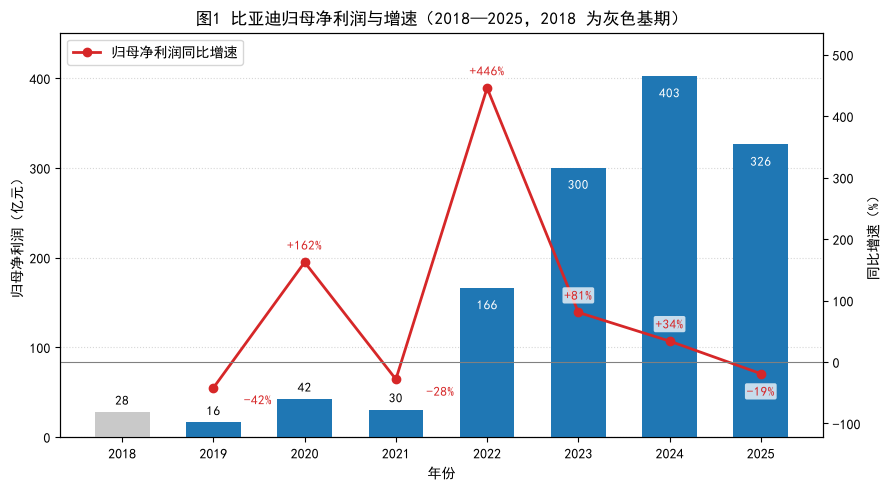

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
years_bar = merged["year"]
colors = ["#c9c9c9" if y == 2018 else "#1f77b4" for y in years_bar]
ax.bar(years_bar, merged["归母净利润(亿元)"], color=colors, width=0.6, zorder=3)
for x, v in zip(years_bar, merged["归母净利润(亿元)"]):
    if v >= 60:
        ax.text(x, v - 12, f"{v:.0f}", ha="center", va="top", fontsize=9, color="white", zorder=4)
    else:
        ax.text(x, v + 8, f"{v:.0f}", ha="center", fontsize=9, zorder=4)
ax.set_xlabel("年份")
ax.set_ylabel("归母净利润（亿元）")
ax.set_title("图1 比亚迪归母净利润与增速（2018—2025，2018 为灰色基期）")
ax.set_xticks(list(years_bar))
ax.set_ylim(0, merged["归母净利润(亿元)"].max() * 1.12)
ax.grid(axis="y", ls=":", alpha=0.5, zorder=0)

ax2 = ax.twinx()
g = tbl["净利润增速%"]
ax2.plot(g.index, g.values, "o-", color="#d62728", lw=2, label="归母净利润同比增速")
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_ylabel("同比增速（%）")
ax2.set_ylim(g.min() - 80, g.max() + 90)
g_offsets = {2019: (22, -12), 2021: (22, -12)}   # 避免与柱顶数值标签碰撞
for x, v in zip(g.index, g.values):
    dx, dy = g_offsets.get(int(x), (0, -16 if v < 0 else 9))
    ax2.annotate(f"{v:+.0f}%", (x, v), textcoords="offset points", xytext=(dx, dy),
                 ha="left" if int(x) in g_offsets else "center", fontsize=9,
                 color="#d62728", zorder=6,
                 bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax2.legend(loc="upper left")
fig.tight_layout()

# 程序化自检：标签两两不重叠
fig.canvas.draw()
rend = fig.canvas.get_renderer()
texts = list(ax.texts) + list(ax2.texts)
bbs = [t.get_window_extent(renderer=rend) for t in texts]
ov = [(texts[i].get_text(), texts[j].get_text())
      for i in range(len(bbs)) for j in range(i + 1, len(bbs)) if bbs[i].overlaps(bbs[j])]
assert not ov, f"标签重叠: {ov}"
print(f"自检通过：{len(texts)} 个文本标签两两无重叠")
plt.show()

**图2　后复权价走势与年度收益率（股价端）**

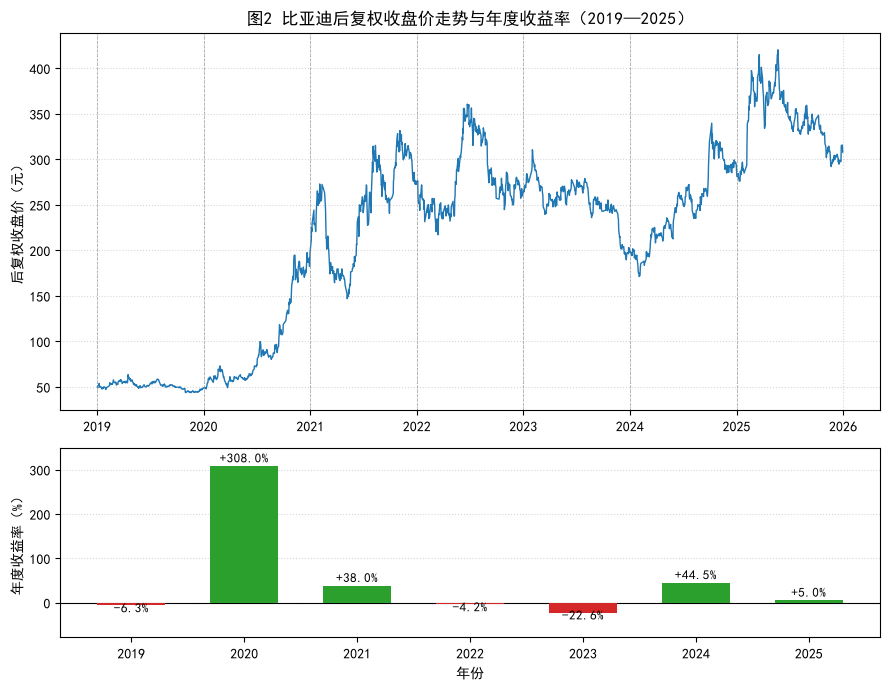

In [12]:
d1925 = df[(df["trade_date"] >= "20190101") & (df["trade_date"] <= "20251231")].copy()
d1925["dt"] = pd.to_datetime(d1925["trade_date"])
assert len(d1925) > 1650, "日线数据不足"

fig, (axa, axb) = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw={"height_ratios": [2, 1]})
axa.plot(d1925["dt"], d1925["close_hfq"], color="#1f77b4", lw=1)
axa.set_title("图2 比亚迪后复权收盘价走势与年度收益率（2019—2025）")
axa.set_ylabel("后复权收盘价（元）")
axa.grid(ls=":", alpha=0.5)
for y in range(2019, 2026):
    axa.axvline(pd.Timestamp(f"{y}-01-01"), color="gray", lw=0.6, ls="--", alpha=0.6)

axb.bar(tbl.index, tbl["股价收益率%"],
        color=["#2ca02c" if v >= 0 else "#d62728" for v in tbl["股价收益率%"]],
        width=0.6, zorder=3)
for x, v in zip(tbl.index, tbl["股价收益率%"]):
    axb.text(x, v + (8 if v >= 0 else -16), f"{v:+.1f}%", ha="center", fontsize=9)
axb.axhline(0, color="black", lw=0.8)
axb.set_ylim(tbl["股价收益率%"].min() - 55, tbl["股价收益率%"].max() + 40)
axb.set_xlabel("年份")
axb.set_ylabel("年度收益率（%）")
axb.set_xticks(list(tbl.index))
axb.grid(axis="y", ls=":", alpha=0.5, zorder=0)
fig.tight_layout()
plt.show()

**图3　盈利累计指数 vs 股价累计指数（趋势同步性的核心图，2018 年末 = 100）**

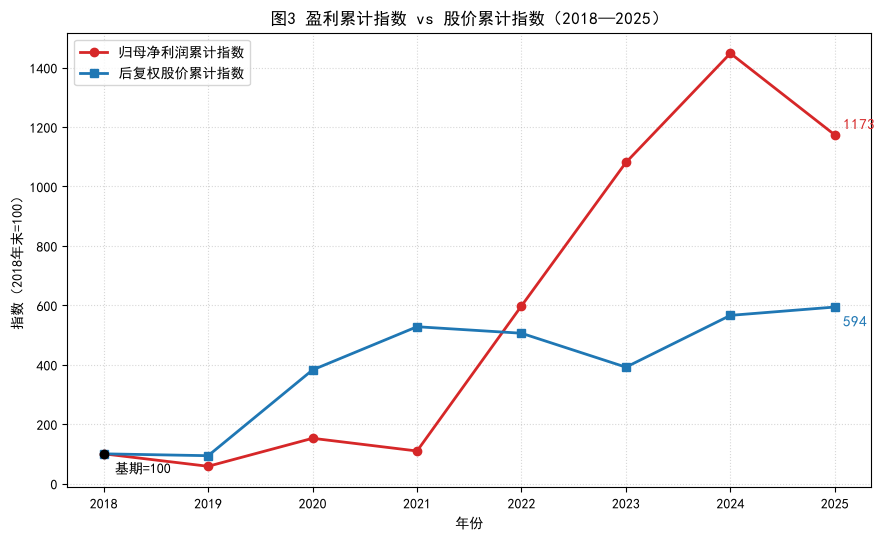

In [13]:
yrs = [2018] + list(tbl.index)
np_line = [100.0] + list(tbl["盈利指数"])
px_line = [100.0] + list(tbl["股价指数"])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(yrs, np_line, "o-", color="#d62728", lw=2, label="归母净利润累计指数")
ax.plot(yrs, px_line, "s-", color="#1f77b4", lw=2, label="后复权股价累计指数")
ax.scatter([2018], [100], color="black", zorder=5)
ax.annotate("基期=100", (2018, 100), textcoords="offset points", xytext=(8, -14), fontsize=10)
ax.annotate(f"{np_line[-1]:.0f}", (2025, np_line[-1]), textcoords="offset points",
            xytext=(6, 4), color="#d62728", fontsize=11)
ax.annotate(f"{px_line[-1]:.0f}", (2025, px_line[-1]), textcoords="offset points",
            xytext=(6, -14), color="#1f77b4", fontsize=11)
ax.set_xlabel("年份")
ax.set_ylabel("指数（2018年末=100）")
ax.set_title("图3 盈利累计指数 vs 股价累计指数（2018—2025）")
ax.set_xticks(yrs)
ax.grid(ls=":", alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

**图4　盈利增速 vs 股价收益率散点图（幅度同步性，n=7）**

自检通过：8 个标签无重叠；r=0.1180, ρ=0.1429


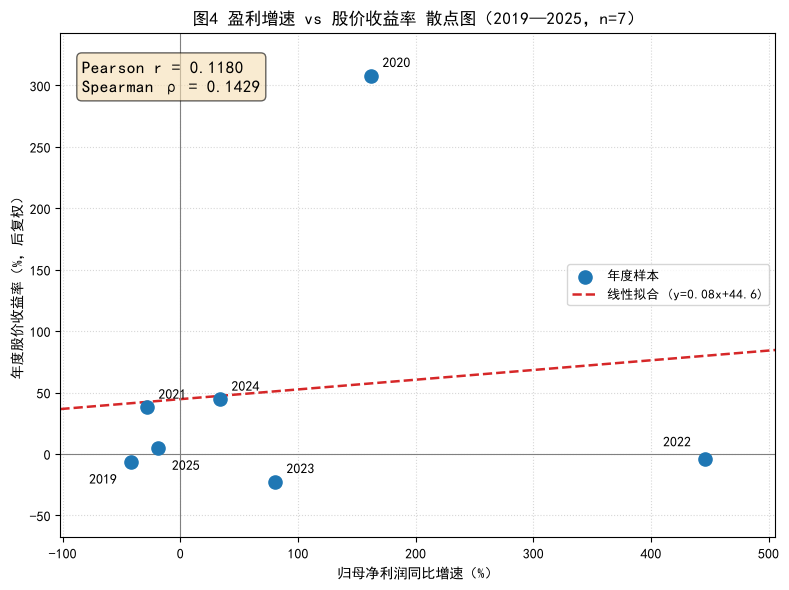

In [14]:
x = tbl["净利润增速%"].to_numpy()
y = tbl["股价收益率%"].to_numpy()
r = float(np.corrcoef(x, y)[0, 1])
rho = float(pd.Series(x).rank().corr(pd.Series(y).rank()))   # Spearman = 秩的Pearson
slope, intercept = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, s=90, color="#1f77b4", zorder=4, label="年度样本")
xs = np.linspace(x.min() - 60, x.max() + 60, 50)
ax.plot(xs, slope * xs + intercept, "--", color="#d62728", lw=1.8,
        label=f"线性拟合 (y={slope:.2f}x+{intercept:.1f})")
offsets = {2019: ((-10, -16), "right"), 2020: ((8, 6), "left"), 2021: ((8, 6), "left"),
           2022: ((-10, 9), "right"), 2023: ((8, 6), "left"), 2024: ((8, 6), "left"),
           2025: ((10, -16), "left")}
for xi, yi, yr in zip(x, y, tbl.index):
    off, ha = offsets[int(yr)]
    ax.annotate(str(yr), (xi, yi), textcoords="offset points", xytext=off,
                ha=ha, fontsize=10)
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlim(x.min() - 60, x.max() + 60)
ax.set_ylim(y.min() - 45, y.max() + 35)
ax.set_xlabel("归母净利润同比增速（%）")
ax.set_ylabel("年度股价收益率（%，后复权）")
ax.set_title("图4 盈利增速 vs 股价收益率 散点图（2019—2025，n=7）")
ax.text(0.03, 0.95, f"Pearson r = {r:.4f}\nSpearman ρ = {rho:.4f}",
        transform=ax.transAxes, va="top", fontsize=12,
        bbox=dict(boxstyle="round", fc="wheat", alpha=0.6))
ax.grid(ls=":", alpha=0.5)
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()

fig.canvas.draw()
rend = fig.canvas.get_renderer()
texts = list(ax.texts)
bbs = [t.get_window_extent(renderer=rend) for t in texts]
ov = [(texts[i].get_text(), texts[j].get_text())
      for i in range(len(bbs)) for j in range(i + 1, len(bbs)) if bbs[i].overlaps(bbs[j])]
assert not ov, f"标签重叠: {ov}"
print(f"自检通过：{len(texts)} 个标签无重叠；r={r:.4f}, ρ={rho:.4f}")
plt.show()

**图5　比亚迪 vs 沪深300 累计表现（区分公司因素与市场因素）**

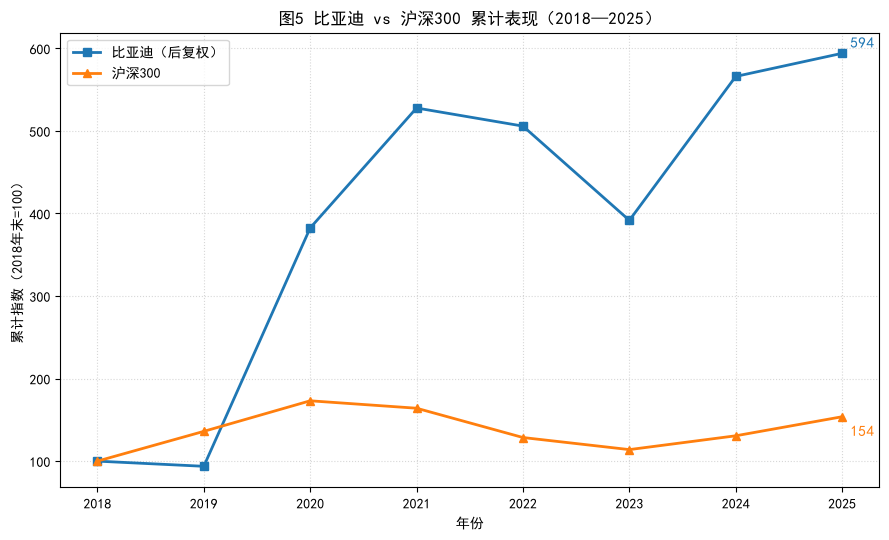

In [15]:
hs = [100.0] + list(idx_cum)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(yrs, [100.0] + list(tbl["股价指数"]), "s-", color="#1f77b4", lw=2, label="比亚迪（后复权）")
ax.plot(yrs, hs, "^-", color="#ff7f0e", lw=2, label="沪深300")
ax.set_xlabel("年份")
ax.set_ylabel("累计指数（2018年末=100）")
ax.set_title("图5 比亚迪 vs 沪深300 累计表现（2018—2025）")
ax.set_xticks(yrs)
ax.grid(ls=":", alpha=0.5)
ax.legend()
ax.annotate(f"{tbl['股价指数'].iloc[-1]:.0f}", (2025, tbl["股价指数"].iloc[-1]),
            textcoords="offset points", xytext=(6, 4), color="#1f77b4", fontsize=11)
ax.annotate(f"{hs[-1]:.0f}", (2025, hs[-1]), textcoords="offset points",
            xytext=(6, -14), color="#ff7f0e", fontsize=11)
fig.tight_layout()
plt.show()

### 3.4 量化分析：同步性指标计算

In [16]:
same_n = int(tbl["是否同向"].sum())
pearson_r = float(tbl["净利润增速%"].corr(tbl["股价收益率%"]))
spearman_rho = float(pd.Series(tbl["净利润增速%"]).rank().corr(
    pd.Series(tbl["股价收益率%"]).rank()))

print("=" * 60)
print(f"方向同步：同向年份 {same_n}/7 = {same_n / 7:.1%}")
print(f"幅度同步：Pearson r = {pearson_r:.4f}，Spearman ρ = {spearman_rho:.4f}")

# 滞后1年对照：盈利增速_t vs 股价收益率_{t+1}（n=6）
lx = tbl["净利润增速%"].iloc[:-1].reset_index(drop=True)
ly = tbl["股价收益率%"].iloc[1:].reset_index(drop=True)
lag_r = float(lx.corr(ly))
print(f"滞后对照：盈利增速_t vs 收益率_t+1，n=6，Pearson r = {lag_r:.4f}")

# 基准对比
total_byd = float(px[2025] / px[2018] - 1)
total_hs = float(idx_px[2025] / idx_px[2018] - 1)
print(f"7年累计收益：比亚迪 {total_byd:.2%}，沪深300 {total_hs:.2%}，"
      f"超额 {total_byd - total_hs:.2%}")
print("=" * 60)

# 分年符号对照
print("\n分年对照（增速 / 收益率 / 是否同向）：")
for yr, row in tbl.iterrows():
    print(f"  {yr}: {row['净利润增速%']:+8.2f}% / {row['股价收益率%']:+8.2f}% / "
          f"{'同向' if row['是否同向'] else '反向'}")

方向同步：同向年份 3/7 = 42.9%
幅度同步：Pearson r = 0.1180，Spearman ρ = 0.1429
滞后对照：盈利增速_t vs 收益率_t+1，n=6，Pearson r = -0.4742
7年累计收益：比亚迪 494.04%，沪深300 53.79%，超额 440.26%

分年对照（增速 / 收益率 / 是否同向）：
  2019:   -41.94% /    -6.25% / 同向
  2020:  +162.33% /  +307.99% / 同向
  2021:   -28.08% /   +37.99% / 反向
  2022:  +445.88% /    -4.16% / 反向
  2023:   +80.73% /   -22.57% / 反向
  2024:   +34.00% /   +44.51% / 同向
  2025:   -18.97% /    +4.95% / 反向


### 3.5 问题解答

按照第二部分**预注册的判定规则**，用上面的实际计算结果逐条对照：

1. **方向同步**：同向年份 **3/7 = 42.9%**，满足“同向 ≤ 3/7 → 不同步”的判定条件。
2. **幅度同步**：Pearson **r = 0.1180**（< 0.2），Spearman **ρ = 0.1429**，两个条件均指向“不同步”。
3. **趋势同步**（图3）：2019—2021 年股价指数（93.8 → 527.8）大幅领先盈利指数（58.1 → 109.5）；2022—2024 年盈利指数反超并冲高至 1448，而股价指数在 2023 年反而回落至 391.7；两条曲线仅在 2019、2020、2024 三个年份同向。
4. **滞后对照**：滞后 1 年的 r = **−0.4742**，不但不支持同步，方向还是负的——“今年盈利好、明年股价涨”的传导关系在本样本中不成立。
5. **基准对照**（图5）：7 年间比亚迪累计 +494.04%，沪深 300 累计 +53.79%，**大幅跑赢大盘**；但 2022、2023 年比亚迪股价分别下跌 4.16%、22.57%，同期沪深 300 也下跌 21.63%、11.38%，说明这两年股价下跌有相当部分来自市场整体因素，而非公司盈利本身（同期盈利分别 +445.88%、+80.73%）。

> **回答：不同步。** 无论按方向（3/7 同向）、幅度（r=0.1180）还是趋势（图 3 曲线多次交叉背离），2019—2025 年比亚迪的盈利增长与其股价表现在**年度节奏上不同步**；二者的联系主要体现在**长期总量方向**上（7 年间盈利指数 1173、股价指数 594，均远高于基期 100），即“**长期方向一致、年度节奏不同步**”。

## 四、研究结论与经验总结

### （一）研究结论

1. **主结论：2019—2025 年比亚迪的盈利增长与股价表现不同步。** 7 个年度样本中仅 3 年同向（42.9%），Pearson r = 0.1180、Spearman ρ = 0.1429，均低于 0.2 的判定阈值；滞后 1 年对照 r = −0.4742，也不支持滞后传导。

2. **分阶段看，背离集中出现在盈利爆发期。** 2019、2020、2024 三年同向（2020 年利润 +162.33% 对应股价 +307.99%，为唯一强共振年份）；而 2021—2023 年盈利从 30.45 亿元跃升至 300.41 亿元期间，股价却在 2022（−4.16%）、2023（−22.57%）连续两年下跌；2025 年利润下滑 18.97%，股价反而上涨 4.95%。

3. **长期总量方向一致，且显著跑赢大盘。** 7 年间归母净利润累计指数达 1173、股价累计指数 594（沪深 300 仅 154），比亚迪累计收益 +494.04%、超额收益约 440 个百分点——“盈利增长”与“股价上涨”在十年尺度上并存，但在年度尺度上并不同步。

4. **原因的合理解释（基于数据）：** 股价定价的不是“当期利润”，而是“预期”。2022 年利润 +445.88% 的原因之一是 2021 年基数低（30.45 亿元）；2022—2023 年比亚迪股价下跌与沪深 300 同期下跌（−21.63%、−11.38%）并存，说明市场系统性风险贡献了相当部分跌幅；2025 年利润下滑而股价上涨，则与收入端仍增长 3.46%、境外收入占比达 38.7% 等结构性因素共同作用于市场预期相符。**相关关系本身不能证明因果，此结论限于本样本。**

### （二）经验总结（数据处理方面）

1. **复权是收益率计算的生命线。** 2025-07-29 比亚迪复权因子从 1.038 跳至 3.150，未复权收盘价从 282.66 元变为 97.72 元（表面 −65%），后复权价却是 293.29 → 307.81（实际 +4.95%）。不复权会得出完全相反的结论。
2. **财务数据必须去重并核对口径。** 利润表原始 13 行经 `report_type='1'` + 最新公告去重后才得到 8 期；净利率口径为“净利润(含少数股东)”，与归母口径不同，需用自算值与接口值交叉验证（本例最大差异仅 0.005）。
3. **接口返回值不能假设单位，要验证。** 通过“自算净利率 vs `netprofit_margin`”“自算增速 vs `netprofit_yoy`”两条独立验证链（差异 0.005 / 0.057），确认了百分数单位与归母增速口径后才用于作图。
4. **用断言（assert）把验证固化到代码里。** 连乘校验、基期 =100、期数 =8、标签无重叠等 10 余处断言，使任何数据异常都会立即报错，而不是悄悄进入结论。
5. **研究设计上先声明判定规则再看数据**（预注册），避免“先看结果再定标准”的循环论证；同时清楚标注 n=7 小样本、自然年对齐与财报披露时滞等局限。